In [1]:
import matplotlib.pyplot as plt
import astropy.units as u
import numpy as np
import lsst.daf.butler as DafButler
import lsst.summit.utils.plotting as splot
from astropy.coordinates import SkyCoord
from lsst.pipe.tasks.visualizeVisit import (
    VisualizeBinExpConfig,
    VisualizeBinExpTask,
    VisualizeMosaicExpConfig,
    VisualizeMosaicExpTask,
)
from PIL import Image

from lsst.summit.utils.utils import getCameraFromInstrumentName
from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel 


from astropy.stats import SigmaClip
from tqdm import tqdm, trange

from photutils.background import Background2D, MedianBackground

# %matplotlib inline
# %matplotlib widget




In [2]:
def bin_image(image, camera, binning=8):
    visualizeBinExpConfig = VisualizeBinExpConfig()
    visualizeBinExpConfig.binning = binning
    visualizeBinExpTask = VisualizeBinExpTask(config=visualizeBinExpConfig)
    return visualizeBinExpTask.run(inputExp=image, camera=camera).outputExp

def doStarless(img):
    kernel = make_2dgaussian_kernel(5, size=3)   
    threshold = detect_threshold(img, 5.)
    segment_map = detect_sources(img, threshold, npixels=1)
    
    footprint = circular_footprint(radius=3)
    dilateMask = segment_map.make_source_mask(footprint=footprint)
    dilateAndSmoothMask = convolve(dilateMask, kernel)

    starlessImg = np.where(dilateAndSmoothMask != 0,np.median(img), img)
    return starlessImg
def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

def so_deg(val):
    return (float(val)*u.rad).to(u.deg).value

In [5]:
#Collections=['LSSTComCam/runs/nightlyValidation']
butler = DafButler.Butler('embargo', collections=['u/ataranto/lsst_outputs'], instrument='LSSTCam')
registry = butler.registry
camera = getCameraFromInstrumentName("LSSTCam")
day_obs=20250528

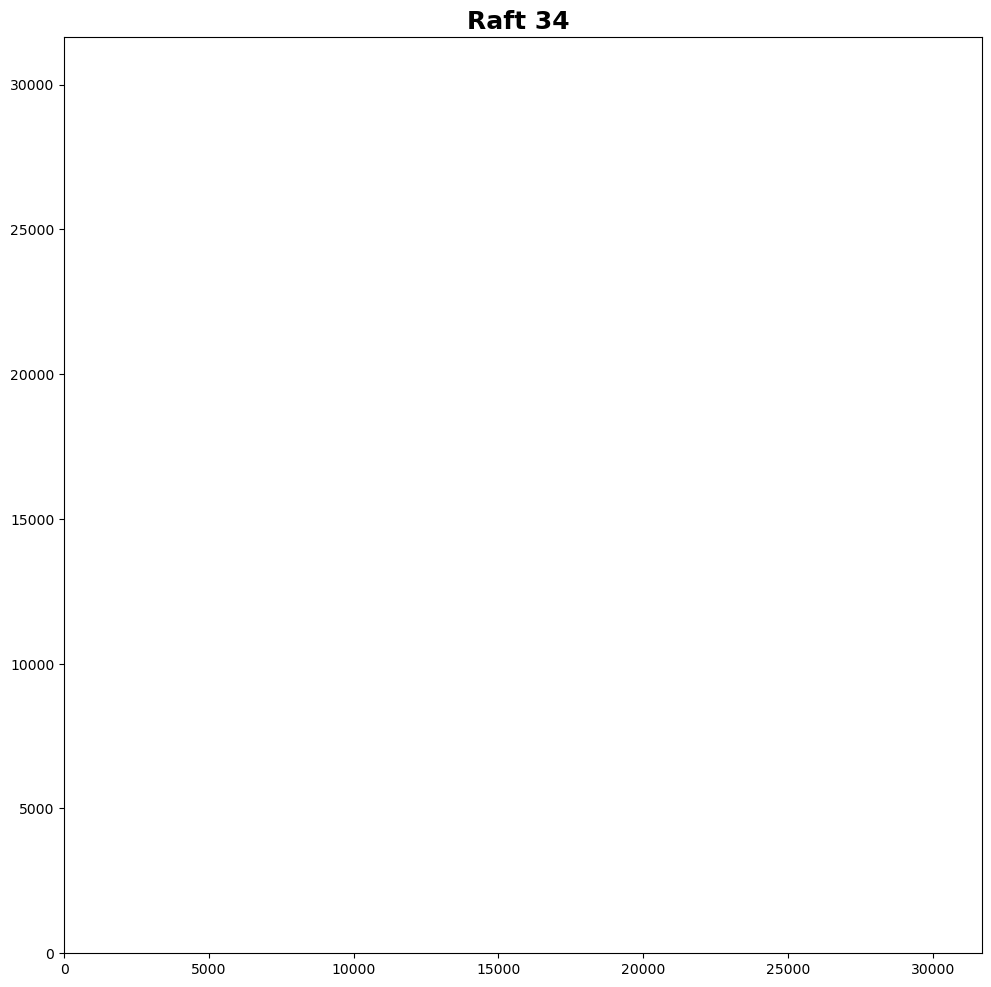

In [ ]:
from astropy.io import fits


Dref= list(registry.queryDatasets('preliminary_visit_image', where=f"visit={2025051900386} and detector in (153..161)"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
exposures = [butler.get(dr) for dr in Dref]
sigma_clip = SigmaClip(sigma=3.0)
bkg_estimator = MedianBackground()
binning = 2
exposures_binned = [bin_image(exposure, camera, binning) for exposure in exposures]

for i, exp in enumerate(exposures_binned):    # 
    bkg = Background2D(exp.image.array, (70, 70), filter_size=(3, 3), sigma_clip=sigma_clip) #, bkg_estimator=bkg_estimator)
    starlessImg = doStarless(exp.image.array-bkg.background)
    exp.image.array = starlessImg
    exposures_binned[i] = exp

visualizeMosaicExpConfig = VisualizeMosaicExpConfig()
visualizeMosaicExpConfig.binning = binning
visualizeMosaicExpTask = VisualizeMosaicExpTask(config=visualizeMosaicExpConfig)
mosaic = visualizeMosaicExpTask.run(inputExps=exposures_binned, camera=camera).outputData   

fig=splot.plot(mosaic.array, stretch='log',percentile=98,cmap='plasma', showCompass=False)    
ax=fig.get_axes()
ax[0].set_title('Raft 34 ', fontsize=18, fontweight='bold')

non_nan_indices = np.argwhere(~np.isnan(mosaic.array))
if non_nan_indices.size > 0:
    y_min, x_min = non_nan_indices.min(axis=0)
    y_max, x_max = non_nan_indices.max(axis=0)
    ax[0].set_xlim(x_min, x_max)
    ax[0].set_ylim(y_min, y_max)
plt.tight_layout()

# plt.savefig(f"long_tail_2025051500440.png")
# plt.show()
# plt.close()


PLOT THE CORNER DETECTOR WHERE AD MAPS THE MOTION OF THE WINGS THROUGH ~60 EXPOSURES 

alpha cen off axis:    1.9934381194660957 deg ///    7176.377230077945  arcsec 
visit    2025052800609
alpha cen off axis:    1.9934381194660957 deg ///    7176.377230077945  arcsec 
-----------------


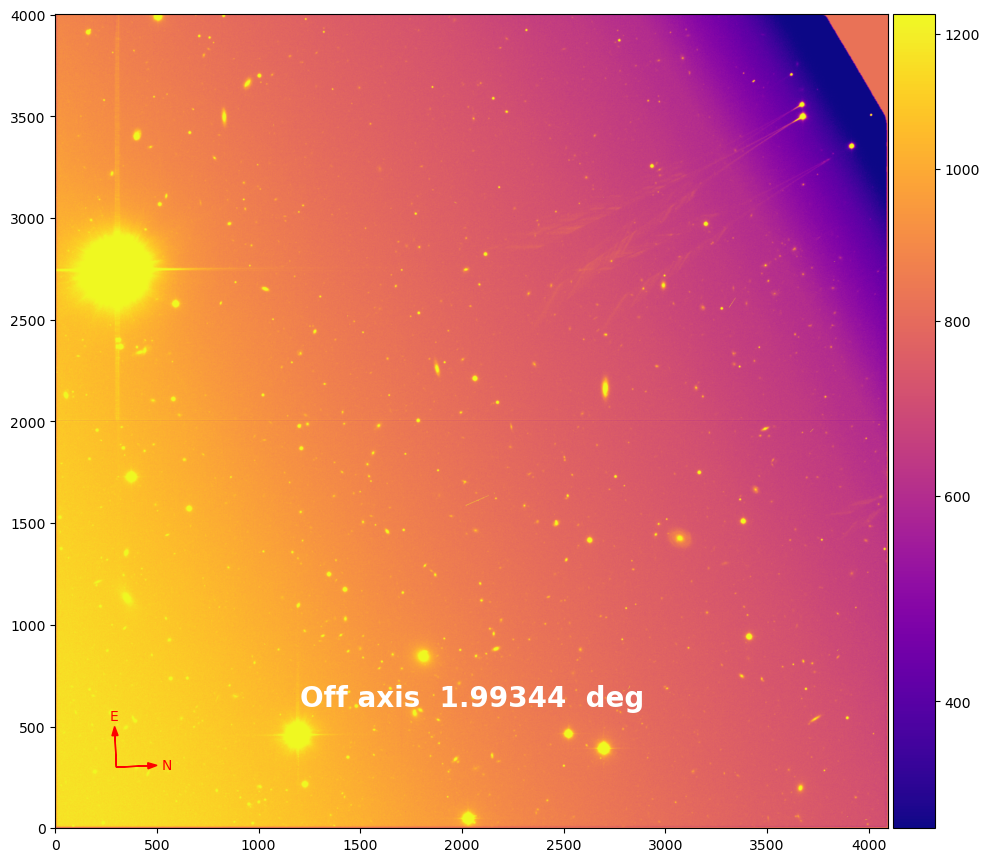

In [ ]:
# al_hms='1h37m44.27s'
# al_dms='-57d13m55.6s'
al_hms='0h43m36.61s'
al_dms='-17d59m12.8s'
alpha = SkyCoord(ra=al_hms, dec=al_dms, unit=(u.hourangle, u.deg), frame='icrs')
day_obs=20250528
Dref = list(registry.queryDatasets('post_isr_image', where=f"visit={2025112500019} and detector=94"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
# Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
dataImgs = [butler.get(dr) for dr in Dref]
wcs = dataImgs[0].wcs #.getFitsMetadata().items()
cra,cdec = wcs.getSkyOrigin()
center = SkyCoord(ra=so_deg(cra)*u.deg, dec=so_deg(cdec)*u.deg, frame='icrs')
print('alpha cen off axis:   ', alpha.separation(center).deg, 'deg ///   ',alpha.separation(center).deg*3600.0, ' arcsec ' )
# hold=wcs
# for seq in range(609,610):
#     plt.close('all')
#     visit=day_obs*100000+seq
#     print('visit   ',visit)
#     Dref_uns = list(registry.queryDatasets('post_isr_image', where=f"visit={2025081700217} and detector=161"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
#     Dref=sorted( Dref_uns, key = lambda x : x.dataId['detector'] )
#     exposures = [butler.get(dr) for dr in Dref]
#     wcs = exposures[0].wcs
#     center_ra, center_dec = wcs.getSkyOrigin()
#     center = SkyCoord(ra=so_deg(center_ra)*u.deg, dec=so_deg(center_dec)*u.deg, frame='icrs')
  
#     print('alpha cen off axis:   ', alpha.separation(center).deg, 'deg ///   ',alpha.separation(center).deg*3600.0, ' arcsec ' )
#     print('-----------------')
#     hold=wcs
#     fig=splot.plot(exposures[0], stretch='log',percentile=98,cmap='plasma')    
#     ax=fig.get_axes()
#     ax[0].annotate(
#         f"Off axis  {alpha.separation(center).deg:.5f}  deg",
#         xy=(0.5, 0.15),
#         xycoords='axes fraction',
#         ha='center',
#         fontsize=20,
#         color='white',
#         fontweight='bold'
#     )
   
    plt.tight_layout()

    # plt.savefig(f"wing_visit{visit}.png")
    # plt.show()
    # plt.close()
    




PRODUCE A MOSAIC WITH THE EVOLUTION OF THE WINGS AS THE OFF ACIS ANGLE INCREASE 

In [ ]:

rows, cols = 3, 4
image_paths = [f"wing_visit{visit}.png" for visit in range(2025051500393,2025051500467,6)]
image_paths.sort()
images = [Image.open(path) for path in image_paths]
img_width, img_height = images[0].size
mosaic = Image.new('RGB', (cols * img_width, rows * img_height))
for index, img in enumerate(images):
    row = index // cols
    col = index % cols
    mosaic.paste(img, (col * img_width, row * img_height))

# Save or show
mosaic.save("mosaic.jpg")
# mosaic.show()

CELL TO ANALYZE THE CLOCK ROTATION TEST BLOCK T516

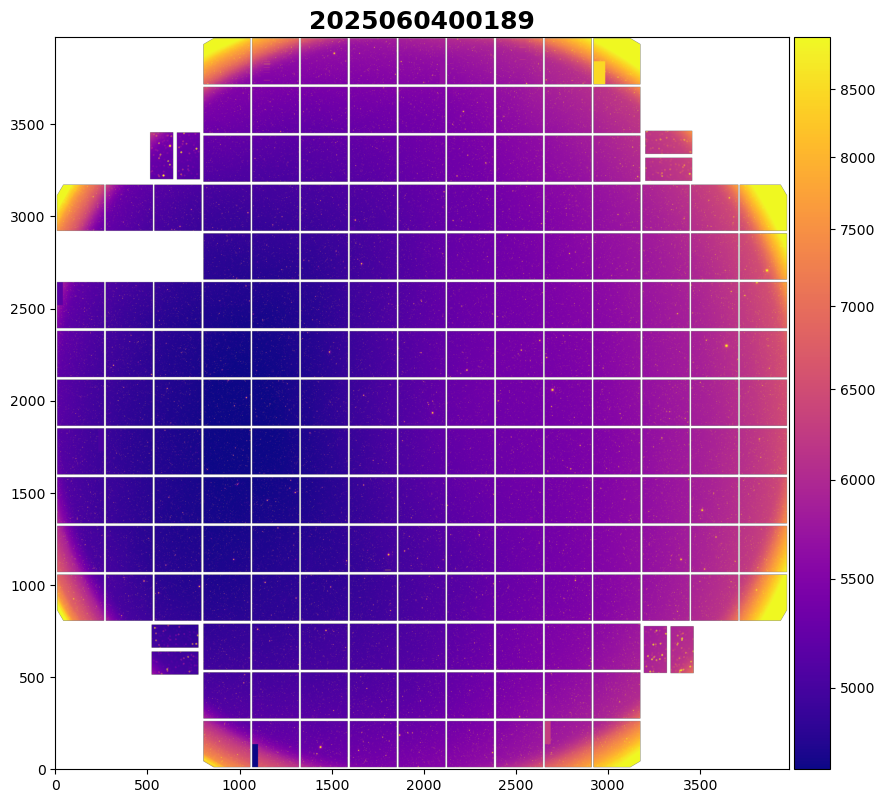

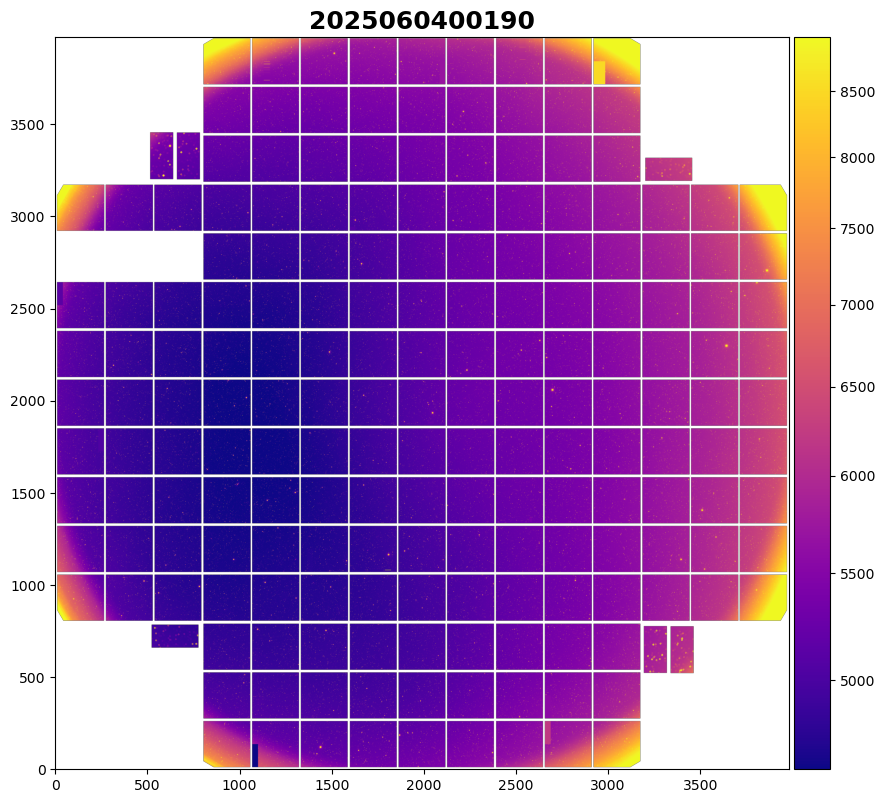

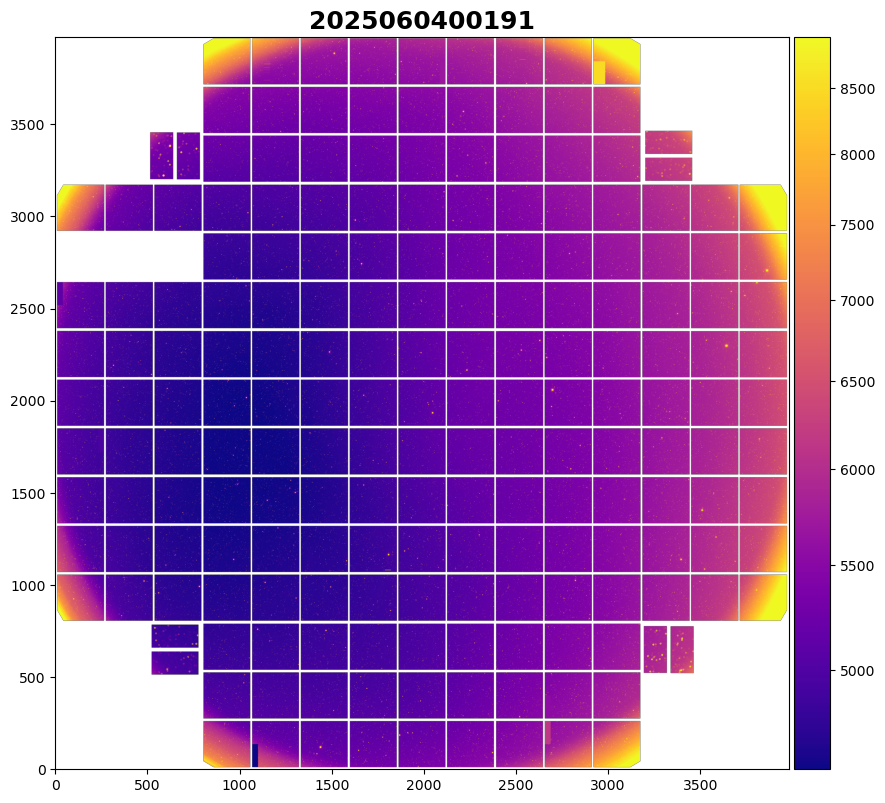

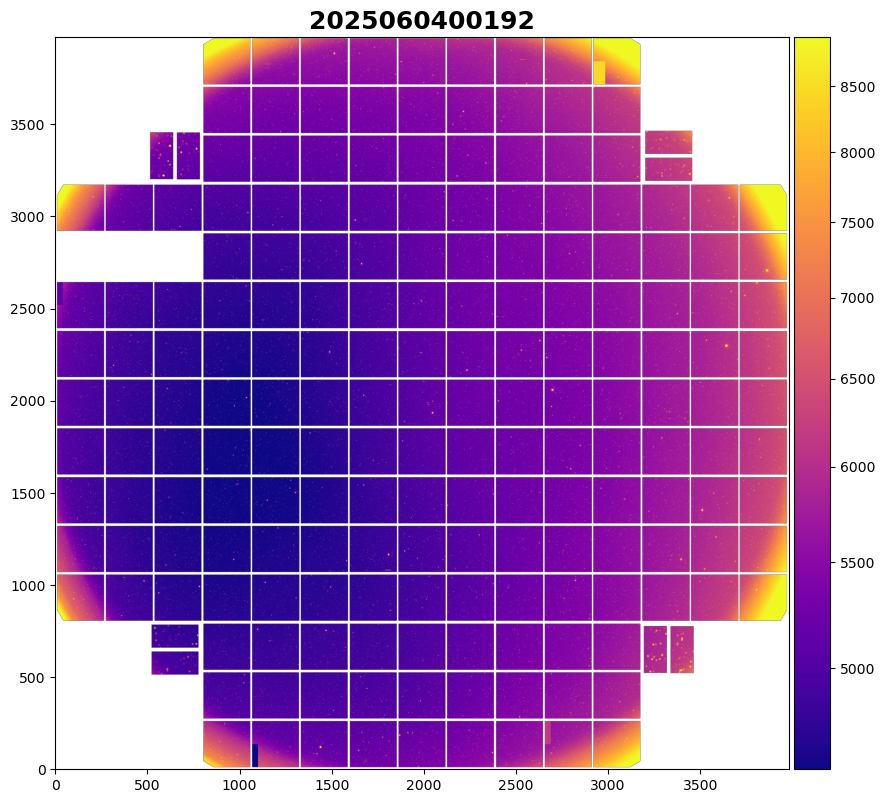

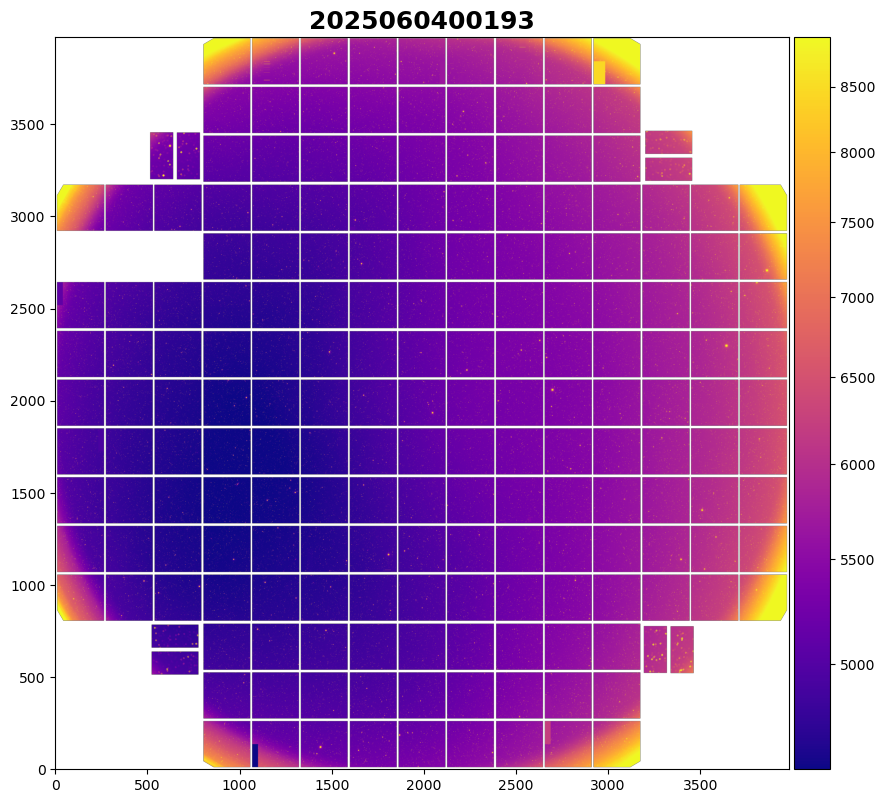

In [ ]:
from astropy.io import fits
stack=None
for i in range(0,9):
    plt.close('all')
    visit=2025060400189+i
    Dref= list(registry.queryDatasets('post_isr_image', where=f"visit={visit}"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
    exposures = [butler.get(dr) for dr in Dref]
    sigma_clip = SigmaClip(sigma=3.0)
    bkg_estimator = MedianBackground()
    binning = 16
    exposures_binned = [bin_image(exposure, camera, binning) for exposure in exposures]

    # for i, exp in enumerate(exposures_binned):    # 
    #     bkg = Background2D(exp.image.array, (70, 70), filter_size=(3, 3), sigma_clip=sigma_clip) #, bkg_estimator=bkg_estimator)
    #     starlessImg = doStarless(exp.image.array-bkg.background)
    #     exp.image.array = starlessImg
    #     exposures_binned[i] = exp

    visualizeMosaicExpConfig = VisualizeMosaicExpConfig()
    visualizeMosaicExpConfig.binning = binning
    visualizeMosaicExpTask = VisualizeMosaicExpTask(config=visualizeMosaicExpConfig)
    mosaic = visualizeMosaicExpTask.run(inputExps=exposures_binned, camera=camera).outputData   
    # if stack is None:
    #         stack = mosaic.array
    # else:
    #         stack += mosaic.array
    # print('im1')
    
    fig = splot.plot(mosaic.array, stretch='log',percentile=98,cmap='plasma', showCompass=False)    
    ax=fig.get_axes()
    ax[0].set_title(f'{visit}', fontsize=18, fontweight='bold')
    plt.show()
    # non_nan_indices = np.argwhere(~np.isnan(mosaic.array))
    # if non_nan_indices.size > 0:
    #     y_min, x_min = non_nan_indices.min(axis=0)
    #     y_max, x_max = non_nan_indices.max(axis=0)
    #     ax[0].set_xlim(x_min, x_max)
    #     ax[0].set_ylim(y_min, y_max)
    # plt.tight_layout()

# plt.savefig(f"long_tail_2025051500440.png")
# plt.show()
# plt.close()


In [ ]:
fits.writeto("wing_clock.fits", stack, overwrite=True)
